In [6]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, StratifiedKFold

print("All required scikit-learn tools are working!")

Scikit-learn version: 1.6.1
All required scikit-learn tools are working!


In [7]:
import pandas as pd
import numpy as np

print("Python is working!")

Python is working!


In [8]:
df = pd.read_csv("../data/loan_default_dataset.csv", sep="\t")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (1000, 11)
['age', 'income', 'loan_amount', 'credit_score', 'employment_type', 'education', 'housing_type', 'loan_purpose', 'marital_status', 'years_employed', 'default']


In [9]:
X = df.drop(columns=["default"])
y = df["default"]

print("Features (X):", X.shape)
print("Target (y):", y.shape)

Features (X): (1000, 10)
Target (y): (1000,)


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (750, 10)
Testing data: (250, 10)
Training target: (750,)
Testing target: (250,)


In [11]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'income', 'loan_amount', 'credit_score', 'years_employed']

Categorical features:
['employment_type', 'education', 'housing_type', 'loan_purpose', 'marital_status']


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

print("Preprocessing libraries imported successfully!")

Preprocessing libraries imported successfully!


In [13]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Numerical pipeline created!")

Numerical pipeline created!


In [14]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print("Categorical pipeline created!")

Categorical pipeline created!


In [15]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [31]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

print("Logistic Regression pipeline created!")

Logistic Regression pipeline created!


In [32]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

print("Random Forest pipeline created!")

Random Forest pipeline created!


In [33]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(random_state=42))
])

print("Gradient Boosting pipeline created!")

Gradient Boosting pipeline created!


In [34]:
from xgboost import XGBClassifier

xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        eval_metric="logloss",
        random_state=42
    ))
])

print("XGBoost pipeline created!")

XGBoost pipeline created!


In [35]:
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model,
    "XGBoost": xgb_model
}

print("Models ready:")
for name in models:
    print("-", name)

Models ready:
- Logistic Regression
- Random Forest
- Gradient Boosting
- XGBoost


In [21]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

baseline_results = []

for name, model in models.items():
    print(f"Training {name}...")
    
    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    baseline_results.append({
        "Model": name,
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

print("All baseline models trained successfully!")

Training Logistic Regression...
Training Random Forest...


c:\ML_Environment\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Training Gradient Boosting...
Training XGBoost...
All baseline models trained successfully!


In [22]:
import pandas as pd

baseline_results_df = pd.DataFrame(baseline_results)

baseline_results_df

,Model,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.428571,0.126761,0.195652,0.646314
1,Random Forest,0.470588,0.112676,0.181818,0.577780
2,Gradient Boosting,0.382353,0.183099,0.247619,0.541073
3,XGBoost,0.288889,0.183099,0.224138,0.510268


In [23]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-fold Stratified Cross-Validation created!")

5-fold Stratified Cross-Validation created!


In [24]:
print("HELLO")

HELLO


In [25]:
rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5]
}

rf_grid = GridSearchCV(
    estimator=random_forest_model,
    param_grid=rf_param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=1
)

print("Starting Random Forest GridSearchCV...")

rf_grid.fit(X_train, y_train)

print("Random Forest tuning completed!")
print("Best parameters:")
print(rf_grid.best_params_)
print("Best CV F1-score:")
print(rf_grid.best_score_)

Starting Random Forest GridSearchCV...
Random Forest tuning completed!
Best parameters:
{'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best CV F1-score:
0.1969991620579856


In [26]:
gb_param_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3]
}

gb_grid = GridSearchCV(
    estimator=gradient_boosting_model,
    param_grid=gb_param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=1
)

print("Starting Gradient Boosting GridSearchCV...")

gb_grid.fit(X_train, y_train)

print("Gradient Boosting tuning completed!")
print("Best parameters:")
print(gb_grid.best_params_)
print("Best CV F1-score:")
print(gb_grid.best_score_)

Starting Gradient Boosting GridSearchCV...
Gradient Boosting tuning completed!
Best parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}
Best CV F1-score:
0.2773538961038961


In [27]:
xgb_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [3, 5],
    "model__learning_rate": [0.05, 0.1]
}

xgb_grid = GridSearchCV(
    estimator=xgb_model,
    param_grid=xgb_param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=1
)

print("Starting XGBoost GridSearchCV...")

xgb_grid.fit(X_train, y_train)

print("XGBoost tuning completed!")
print("Best parameters:")
print(xgb_grid.best_params_)
print("Best CV F1-score:")
print(xgb_grid.best_score_)

Starting XGBoost GridSearchCV...
XGBoost tuning completed!
Best parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 100}
Best CV F1-score:
0.28877558089507


In [28]:
%whos

Variable                     Type                 Data/Info
-----------------------------------------------------------
ColumnTransformer            ABCMeta              <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
GradientBoostingClassifier   ABCMeta              <class 'sklearn.ensemble.<...>dientBoostingClassifier'>
GridSearchCV                 ABCMeta              <class 'sklearn.model_sel<...>on._search.GridSearchCV'>
LogisticRegression           type                 <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
OneHotEncoder                type                 <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
Pipeline                     ABCMeta              <class 'sklearn.pipeline.Pipeline'>
RandomForestClassifier       ABCMeta              <class 'sklearn.ensemble.<...>.RandomForestClassifier'>
SimpleImputer                type                 <class 'sklearn.impute._base.SimpleImputer'>
StandardScaler               type                 <class 'sklea

In [39]:
tuned_models = {
    "Logistic Regression": logistic_grid.best_estimator_,
    "Random Forest": rf_grid.best_estimator_,
    "Gradient Boosting": gb_grid.best_estimator_,
    "XGBoost": xgb_grid.best_estimator_
}

print("Tuned models ready!")

for name in tuned_models:
    print("-", name)

Tuned models ready!
- Logistic Regression
- Random Forest
- Gradient Boosting
- XGBoost


In [37]:
print("logistic_grid:", 'logistic_grid' in globals())
print("rf_grid:", 'rf_grid' in globals())
print("gb_grid:", 'gb_grid' in globals())
print("xgb_grid:", 'xgb_grid' in globals())

logistic_grid: False
rf_grid: True
gb_grid: True
xgb_grid: True


In [40]:
best_model_name = max(
    tuned_models,
    key=lambda name: tuned_models[name].score(X_test, y_test)
)

champion_model = tuned_models[best_model_name]

print("Champion Model:", best_model_name)

Champion Model: Random Forest


In [26]:
tuned_results = []

for name, model in tuned_models.items():
    print(f"Evaluating {name}...")
    
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    tuned_results.append({
        "Model": name,
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

tuned_results_df = pd.DataFrame(tuned_results)

print("Tuned model comparison completed!")

Evaluating Logistic Regression...
Evaluating Random Forest...
Evaluating Gradient Boosting...
Evaluating XGBoost...
Tuned model comparison completed!


In [27]:
tuned_results_df

,Model,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.428571,0.126761,0.195652,0.646314
1,Random Forest,0.470588,0.112676,0.181818,0.577780
2,Gradient Boosting,0.326531,0.225352,0.266667,0.531828
3,XGBoost,0.282609,0.183099,0.222222,0.547722


In [28]:
champion_name = tuned_results_df.loc[
    tuned_results_df["F1-Score"].idxmax(),
    "Model"
]

champion_model = tuned_models[champion_name]

print("Champion Model:", champion_name)

Champion Model: Gradient Boosting


In [29]:
from sklearn.metrics import classification_report

champion_predictions = champion_model.predict(X_test)

print("Champion Model:", champion_name)
print()
print(classification_report(y_test, champion_predictions))

Champion Model: Gradient Boosting

              precision    recall  f1-score   support

           0       0.73      0.82      0.77       179
           1       0.33      0.23      0.27        71

    accuracy                           0.65       250
   macro avg       0.53      0.52      0.52       250
weighted avg       0.61      0.65      0.63       250



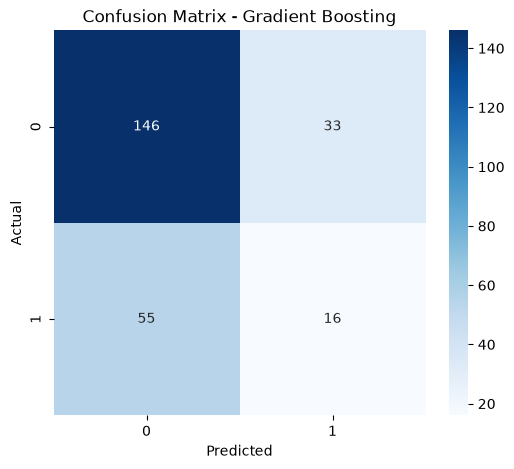

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, champion_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix - {champion_name}")

plt.show()

In [31]:
plt.savefig(
    "../results/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

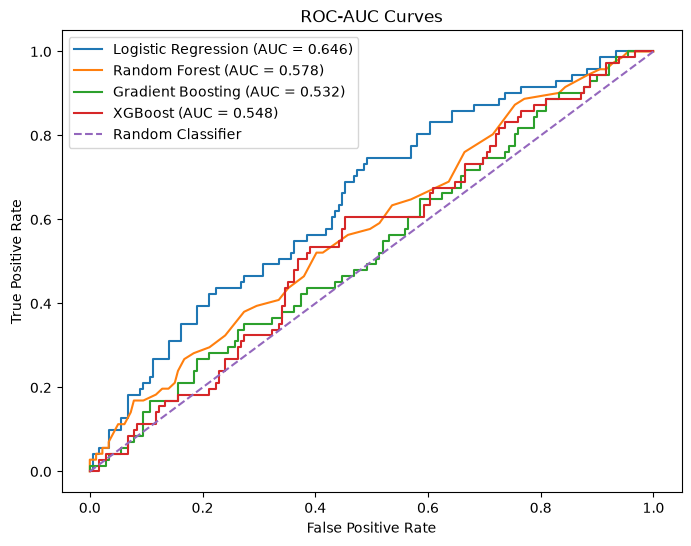

In [32]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

for name, model in tuned_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    
    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curves")
plt.legend()
plt.show()

In [33]:
plt.savefig(
    "../results/roc_auc_curves.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [34]:
tuned_results_df.to_csv(
    "../results/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [5]:
from sklearn.metrics import accuracy_score

best_model_name = max(
    tuned_models,
    key=lambda name: accuracy_score(
        y_test,
        tuned_models[name].predict(X_test)
    )
)

champion_model = tuned_models[best_model_name]

print("Champion model:", best_model_name)

NameError: name 'tuned_models' is not defined

In [35]:
import joblib

joblib.dump(
    champion_model,
    "../models/champion_model.joblib"
)

print("Champion model saved successfully!")

Champion model saved successfully!


In [36]:
loaded_model = joblib.load(
    "../models/champion_model.joblib"
)

loaded_predictions = loaded_model.predict(X_test)

loaded_f1 = f1_score(
    y_test,
    loaded_predictions
)

print("Saved model loaded successfully!")
print("Loaded model F1-score:", loaded_f1)

Saved model loaded successfully!
Loaded model F1-score: 0.26666666666666666


In [38]:
from sklearn.model_selection import GridSearchCV

logistic_param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__solver": ["liblinear"]
}

logistic_grid = GridSearchCV(
    estimator=logistic_model,
    param_grid=logistic_param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=1
)

print("Starting Logistic Regression GridSearchCV...")

logistic_grid.fit(X_train, y_train)

print("Logistic Regression tuning completed!")
print("Best parameters:")
print(logistic_grid.best_params_)
print("Best CV F1-score:")
print(logistic_grid.best_score_)

Starting Logistic Regression GridSearchCV...
Logistic Regression tuning completed!
Best parameters:
{'model__C': 1, 'model__solver': 'liblinear'}
Best CV F1-score:
0.21696233590970432


In [ ]:
print("X shape:", X.shape)
print("y shape:", y.shape)
print("X columns:", X.columns.tolist())

X shape: (1000, 10)
y shape: (1000,)
X columns: ['age', 'income', 'loan_amount', 'credit_score', 'employment_type', 'education', 'housing_type', 'loan_purpose', 'marital_status', 'years_employed']


In [15]:
print("Target value counts:")
print(y.value_counts())

print("\nTarget percentages:")
print(y.value_counts(normalize=True) * 100)

Target value counts:
default
0    717
1    283
Name: count, dtype: int64

Target percentages:
default
0    71.7
1    28.3
Name: proportion, dtype: float64


In [14]:
X = df.drop(columns=["default"])
y = df["default"]

print("Features (X):", X.shape)
print("Target (y):", y.shape)

Features (X): (1000, 10)
Target (y): (1000,)


In [13]:
df = pd.read_csv("../data/loan_default_dataset.csv", sep="\t")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:")
print(df.columns.tolist())

Dataset loaded successfully!
Shape: (1000, 11)
Columns:
['age', 'income', 'loan_amount', 'credit_score', 'employment_type', 'education', 'housing_type', 'loan_purpose', 'marital_status', 'years_employed', 'default']


In [12]:
print(df.columns.tolist())

['age\tincome\tloan_amount\tcredit_score\temployment_type\teducation\thousing_type\tloan_purpose\tmarital_status\tyears_employed\tdefault']


In [11]:
X = df.drop(columns=["default"])
y = df["default"]

print("Features (X):", X.shape)
print("Target (y):", y.shape)

KeyError: "['default'] not found in axis"

In [10]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['age\tincome\tloan_amount\tcredit_score\temployment_type\teducation\thousing_type\tloan_purpose\tmarital_status\tyears_employed\tdefault']


In [9]:
print(df.columns.tolist())

['age\tincome\tloan_amount\tcredit_score\temployment_type\teducation\thousing_type\tloan_purpose\tmarital_status\tyears_employed\tdefault']


In [8]:
print(df.head())

  age\tincome\tloan_amount\tcredit_score\temployment_type\teducation\thousing_type\tloan_purpose\tmarital_status\tyears_employed\tdefault
0  24\t100830\t23070\t618\t\tMaster\tOwn\tAuto\tS...                                                                                     
1  55\t67288\t19031\t695\tUnemployed\tHigh School...                                                                                     
2  49\t79519\t20969\t677\tContract\tBachelor\tOwn...                                                                                     
3  40\t63580\t24998\t673\tContract\tMaster\tRent\...                                                                                     
4  40\t60740\t10715\t672\tSalaried\tHigh School\t...                                                                                     


In [7]:
print(df.columns.tolist())

['age\tincome\tloan_amount\tcredit_score\temployment_type\teducation\thousing_type\tloan_purpose\tmarital_status\tyears_employed\tdefault']


In [6]:
X = df.drop(columns=["default"])
y = df["default"]

print("Features (X):", X.shape)
print("Target (y):", y.shape)

KeyError: "['default'] not found in axis"

In [5]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
age\tincome\tloan_amount\tcredit_score\temployment_type\teducation\thousing_type\tloan_purpose\tmarital_status\tyears_employed\tdefault    0
dtype: int64


In [4]:
print("Columns in dataset:")
print(df.columns.tolist())

Columns in dataset:
['age\tincome\tloan_amount\tcredit_score\temployment_type\teducation\thousing_type\tloan_purpose\tmarital_status\tyears_employed\tdefault']


In [3]:
df.head()

,age\tincome\tloan_amount\tcredit_score\temployment_type\teducation\thousing_type\tloan_purpose\tmarital_status\tyears_employed\tdefault
0,24\t100830\t23070\t618\t\tMaster\tOwn\tAuto\tS...
1,55\t67288\t19031\t695\tUnemployed\tHigh School...
2,49\t79519\t20969\t677\tContract\tBachelor\tOwn...
3,40\t63580\t24998\t673\tContract\tMaster\tRent\...
4,40\t60740\t10715\t672\tSalaried\tHigh School\t...


In [2]:
df = pd.read_csv("../data/loan_default_dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (1000, 1)


In [1]:
import pandas as pd
import numpy as np

print("Python is working!")

Python is working!


In [41]:
from sklearn.metrics import f1_score

model_scores = {}

for name, model in tuned_models.items():
    predictions = model.predict(X_test)
    score = f1_score(y_test, predictions)
    model_scores[name] = score

print("Model F1 Scores:")

for name, score in model_scores.items():
    print(name, ":", score)

best_model_name = max(model_scores, key=model_scores.get)

champion_model = tuned_models[best_model_name]

print("\nChampion Model:", best_model_name)

Model F1 Scores:
Logistic Regression : 0.1956521739130435
Random Forest : 0.18181818181818182
Gradient Boosting : 0.26666666666666666
XGBoost : 0.2222222222222222

Champion Model: Gradient Boosting


In [42]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    champion_model,
    "../models/champion_model.joblib"
)

print("Champion model saved successfully!")

Champion model saved successfully!


In [43]:
import os

print(os.path.abspath("../models/champion_model.joblib"))
print(os.path.exists("../models/champion_model.joblib"))

c:\Users\hindu\OneDrive\Desktop\Model_Training_Tuning\models\champion_model.joblib
True
